# Challenge 3 – Surface material and finish
**Group:** (names) &nbsp; **N =** (2 or 3)

Finish classes come from `annotations/parts.csv` (column `finish`; merge classes with `MERGE`). Features are computed on the **full-resolution** image
inside each part's mask (thin parts are only a few pixels wide, so we do not downscale).

Methods compared (feature families, each with several classifiers): colour statistics, colour histograms, LBP, GLCM, Laws' energies, reflectance cues, and a combination.
Illumination / white balance is handled by a per-image **wood-background normalisation**; highlights by a **specular mask**; both are ablated and stress-tested.

In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.feature import local_binary_pattern, graycomatrix
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix

SEED = 0; np.random.seed(SEED)
IN, ANN, C1, OUT = Path("inputs"), Path("annotations"), Path("outputs/c1"), Path("outputs/c3")
OUT.mkdir(parents=True, exist_ok=True)
EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# ---- parameters (justify in the report) ----
MERGE    = {}            # e.g. {"gray-matt": "stainless"}  (only 4 gray-matt parts -> merge or discuss)
BEST_SEG = "otsu"        # segmentation used in the final run (decision of Challenge 1)
MIN_PART_PX = 30

## 1. Data

In [3]:
parts = pd.read_csv(ANN / "parts.csv", dtype=str)
parts["stem"] = parts["image"].map(lambda s: Path(s).stem)
parts["finish"] = parts["finish"].str.strip().str.lower().replace(MERGE)
parts["type"] = parts["type"].str.strip().str.lower()
finish_map = {(r.stem, int(r.part_id)): r.finish for r in parts.itertuples()}
type_map   = {(r.stem, int(r.part_id)): r.type   for r in parts.itertuples()}
notes_map  = {(r.stem, int(r.part_id)): (r.notes if isinstance(r.notes, str) else "") for r in parts.itertuples()}
stems = sorted(parts.stem.unique())

def find_img(stem): return next(p for p in IN.iterdir() if p.stem == stem and p.suffix.lower() in EXT)
def load_img(stem): return cv2.cvtColor(cv2.imread(str(find_img(stem))), cv2.COLOR_BGR2RGB)
def load_lab(stem, shape):
    g = cv2.imread(str(ANN / f"{stem}_labels.png"), cv2.IMREAD_UNCHANGED); g = g[..., 0] if g.ndim == 3 else g
    return cv2.resize(g, (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST).astype(np.int32) if g.shape != shape[:2] else g.astype(np.int32)
IMG = {s: load_img(s) for s in stems}; GT = {s: load_lab(s, IMG[s].shape) for s in stems}
print(len(stems), "images,", len(parts), "parts"); print(parts.finish.value_counts().to_dict())

10 images, 85 parts
{'zinc-clear': 26, 'black-oxidized': 22, 'stainless': 21, 'zinc-yellow': 12, 'gray-matt': 4}


## 2. Illumination, white balance and highlights
* **White balance / illumination:** the wood is the same material in every image, so its median colour is a built-in reference. Each image is rescaled per channel so that its wood median equals the global reference (computed over the annotated images).
* **Specular highlights:** pixels with a clipped channel (≥ 250) and their 1-px neighbourhood are excluded from colour/texture statistics (their amount is kept as a *feature*, `rf_spec_frac`, because it carries reflectance information).
* **Thin parts:** statistics use the full-resolution image; the part is eroded by ~2 px to avoid edge pixels mixed with wood, and if too few pixels remain the erosion is relaxed (flagged through `n_valid`).

In [4]:
def wood_median(img, lab):
    bg = cv2.erode((lab == 0).astype(np.uint8), np.ones((15, 15), np.uint8)) > 0
    return np.median(img[bg][::40], axis=0)
REF = np.median([wood_median(IMG[s], GT[s]) for s in stems], axis=0); print("reference wood colour (RGB):", REF.round(1))

def apply_wb(img, wood):
    return np.clip(img.astype(np.float32) * (REF / wood), 0, 255).astype(np.uint8)

def perturb_img(img, rng):
    """Stress test: random per-channel gain (white balance / illuminant change) and gamma (exposure)."""
    x = np.clip(img / 255. * (1 + rng.uniform(-.12, .12, 3)), 0, 1) ** rng.uniform(.8, 1.25)
    return (x * 255 + .5).astype(np.uint8)

reference wood colour (RGB): [223.5 176.  102.5]


## 3. Descriptors

In [5]:
K = {"L5": [1, 4, 6, 4, 1], "E5": [-1, -2, 0, 2, 1], "S5": [-1, 0, 2, 0, -1], "R5": [1, -4, 6, -4, 1]}
LAWS = {a + b: np.outer(K[a], K[b]).astype(np.float32) for a in K for b in K}
PAIRS = [("L5E5", "E5L5"), ("L5S5", "S5L5"), ("L5R5", "R5L5"), ("E5E5",), ("E5S5", "S5E5"), ("E5R5", "R5E5"), ("S5S5",), ("S5R5", "R5S5"), ("R5R5",)]
HR = {"L": (0, 256), "a": (-20, 30), "b": (-30, 50), "S": (0, 256)}

def finish_features(img, mask, spec_mask=True):
    ys, xs = np.nonzero(mask); H, W = mask.shape; pad = 6
    y0, y1, x0, x1 = max(ys.min()-pad, 0), min(ys.max()+1+pad, H), max(xs.min()-pad, 0), min(xs.max()+1+pad, W)
    c, m = img[y0:y1, x0:x1], mask[y0:y1, x0:x1]
    dt = ndi.distance_transform_edt(m)
    valid = dt > 1.5
    if valid.sum() < 30: valid = dt > 0.5                     # very thin part: relax erosion
    if valid.sum() < 10: valid = m
    lab = cv2.cvtColor(c, cv2.COLOR_RGB2LAB); hsv = cv2.cvtColor(c, cv2.COLOR_RGB2HSV)
    clipped = c.max(2) >= 250; spec_frac = float(clipped[valid].mean())
    use = valid & ~(cv2.dilate(clipped.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0) if spec_mask else valid
    if use.sum() < 20: use = valid
    gray = lab[..., 0]
    ch = {"L": gray.astype(np.float32), "a": lab[..., 1].astype(np.float32) - 128, "b": lab[..., 2].astype(np.float32) - 128,
          "S": hsv[..., 1].astype(np.float32), "V": hsv[..., 2].astype(np.float32)}
    f = {}
    for k, v in ch.items():                                                   # colour statistics
        x = v[use]; p = np.percentile(x, [10, 50, 90])
        f.update({f"cs_{k}_mean": x.mean(), f"cs_{k}_std": x.std(), f"cs_{k}_p10": p[0], f"cs_{k}_med": p[1], f"cs_{k}_p90": p[2]})
    for k, (lo, hi) in HR.items():                                            # colour histograms
        h, _ = np.histogram(np.clip(ch[k][use], lo, hi - 1e-3), bins=8, range=(lo, hi)); h = h / max(h.sum(), 1)
        f.update({f"ch_{k}{i}": h[i] for i in range(8)})
    lbp = local_binary_pattern(gray, 8, 1, "uniform")                         # LBP (uniform, P=8, R=1)
    h, _ = np.histogram(lbp[use], bins=10, range=(0, 10)); h = h / max(h.sum(), 1)
    f.update({f"lbp_{i}": h[i] for i in range(10)})
    q = np.where(use, gray // 8 + 1, 0).astype(np.uint8)                      # GLCM (level 0 = outside the part)
    P = graycomatrix(q, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=33, symmetric=True, normed=False)[1:, 1:, 0, :].sum(-1).astype(float)
    if P.sum() > 0:
        P /= P.sum(); i, j = np.meshgrid(np.arange(32), np.arange(32), indexing="ij")
        gl = dict(contrast=(P*(i-j)**2).sum(), dissim=(P*abs(i-j)).sum(), homog=(P/(1+(i-j)**2)).sum(),
                  energy=np.sqrt((P**2).sum()), entropy=-(P*np.log(P+1e-12)).sum())
    else: gl = dict(contrast=0, dissim=0, homog=0, energy=0, entropy=0)
    f.update({f"gl_{k}": v for k, v in gl.items()})
    g = gray.astype(np.float32); g = g - cv2.blur(g, (7, 7))                  # Laws' texture energies
    E = {n: np.abs(cv2.filter2D(g, -1, k))[use].mean() for n, k in LAWS.items()}; nrm = E["L5L5"] + 1e-6
    for pr in PAIRS: f[f"lw_{pr[0]}"] = np.mean([E[n] for n in pr]) / nrm
    Lv = ch["L"][valid]; gm = np.hypot(cv2.Sobel(ch["L"], cv2.CV_32F, 1, 0), cv2.Sobel(ch["L"], cv2.CV_32F, 0, 1))
    f.update(rf_spec_frac=spec_frac, rf_hl=np.percentile(Lv, 99) - np.median(Lv), rf_Lstd_rel=Lv.std() / (Lv.mean() + 1),
             rf_grad_rel=gm[use].mean() / (ch["L"][use].mean() + 1), rf_dark_frac=float((Lv < 40).mean()))
    f["n_valid"] = int(use.sum())
    return {k: float(v) for k, v in f.items()}

GROUPS = {"color_stats": "cs_", "color_hist": "ch_", "lbp": "lbp_", "glcm": "gl_", "laws": "lw_", "reflect": "rf_"}
_ex = finish_features(IMG[stems[0]], GT[stems[0]] == 1)
cols = lambda prefixes: [k for k in _ex if any(k.startswith(p) for p in prefixes)]
FEATSETS = {n: cols([p]) for n, p in GROUPS.items()}
FEATSETS["combined"] = cols(["cs_", "lbp_", "lw_", "rf_"])
print({k: len(v) for k, v in FEATSETS.items()})

{'color_stats': 25, 'color_hist': 32, 'lbp': 10, 'glcm': 5, 'laws': 9, 'reflect': 5, 'combined': 49}


In [6]:
VARIANTS = {"full": dict(wb=True, spec=True), "no_wb": dict(wb=False, spec=True), "no_spec": dict(wb=True, spec=False)}
def build(variant, cond):
    v = VARIANTS[variant]; rows = []
    for k, s in enumerate(stems):
        img = IMG[s]
        if cond == "perturbed": img = perturb_img(img, np.random.RandomState(SEED + k))
        if v["wb"]: img = apply_wb(img, wood_median(img, GT[s]))
        for pid in sorted(int(i) for i in np.unique(GT[s][GT[s] > 0])):
            if (s, pid) not in finish_map: continue
            rows.append(dict(image=s, source=s, part_id=pid, type=type_map[(s, pid)], finish=finish_map[(s, pid)],
                             unsure="unsure" in notes_map[(s, pid)], **finish_features(img, GT[s] == pid, v["spec"])))
    return pd.DataFrame(rows)
TABLES = {(v, c): build(v, c) for v in VARIANTS for c in ("clean", "perturbed")}
df = TABLES[("full", "clean")]; df.to_csv(OUT / "features_full_clean.csv", index=False)
print({f"{k[0]}/{k[1]}": len(t) for k, t in TABLES.items()}); print("parts with < 200 valid pixels:", int((df.n_valid < 200).sum()))

{'full/clean': 85, 'full/perturbed': 85, 'no_wb/clean': 85, 'no_wb/perturbed': 85, 'no_spec/clean': 85, 'no_spec/perturbed': 85}
parts with < 200 valid pixels: 0


## 4. Which texture / colour property identifies each finish?
One-vs-rest AUC of every single descriptor, per finish class (white-balance normalised, clean images). Report the top descriptors per class and the best descriptor per family.

,finish,feature,auc,direction
0,black-oxidized,cs_L_mean,1.000,lower
29,black-oxidized,ch_L4,1.000,lower
28,black-oxidized,ch_L3,1.000,lower
112,gray-matt,ch_L1,0.975,higher
125,gray-matt,ch_a6,0.969,lower
126,gray-matt,ch_a7,0.969,lower
240,stainless,gl_dissim,0.918,higher
241,stainless,gl_homog,0.917,lower
232,stainless,lbp_3,0.915,higher
332,zinc-clear,lw_L5R5,0.976,lower


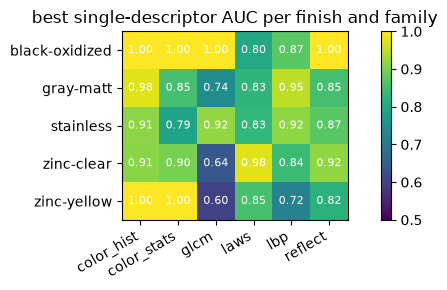

In [7]:
ALLF = [c for c in _ex if c != "n_valid"]; classes = sorted(df.finish.unique()); rows = []
for c in classes:
    y = (df.finish == c).astype(int).values
    for f in ALLF:
        a = roc_auc_score(y, df[f]) if y.min() != y.max() else np.nan
        rows.append(dict(finish=c, feature=f, auc=max(a, 1 - a), direction="higher" if a >= .5 else "lower"))
AUC = pd.DataFrame(rows); AUC.to_csv(OUT / "single_feature_auc.csv", index=False)
top = AUC.sort_values("auc", ascending=False).groupby("finish").head(3).sort_values(["finish", "auc"], ascending=[True, False]); display(top.round(3))
fam = lambda f: next(n for n, p in GROUPS.items() if f.startswith(p))
H = AUC.assign(family=AUC.feature.map(fam)).groupby(["finish", "family"]).auc.max().unstack()
fig, ax = plt.subplots(figsize=(7, 3)); im = ax.imshow(H.values, vmin=.5, vmax=1, cmap="viridis")
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels(H.columns, rotation=30, ha="right"); ax.set_yticks(range(H.shape[0])); ax.set_yticklabels(H.index)
for i in range(H.shape[0]):
    for j in range(H.shape[1]): ax.text(j, i, f"{H.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
plt.colorbar(im); plt.title("best single-descriptor AUC per finish and family"); plt.tight_layout(); plt.savefig(OUT / "finish_vs_family.png", dpi=130); plt.show()

## 5. Methods and evaluation
Feature family × classifier, nested cross-validation **grouped by source image** (a part's neighbours in the same photo never leak into training).
Pooled out-of-fold predictions are scored; the `perturbed` condition re-computes features on images with random white-balance gains and gamma and tests the models trained on clean images.

In [8]:
CLFS = {"svm": (make_pipeline(StandardScaler(), SVC(class_weight="balanced", random_state=SEED)), {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01]}),
        "rf": (RandomForestClassifier(100, class_weight="balanced", random_state=SEED), {"max_depth": [3, None]}),
        "logreg": (make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=3000)), {"logisticregression__C": [0.1, 1, 10]})}

def cv_eval(variant, clf_names, featsets):
    tr_tab, out = TABLES[(variant, "clean")], []
    gkf = GroupKFold(n_splits=min(5, tr_tab.source.nunique()))
    for fold, (tr, te) in enumerate(gkf.split(tr_tab, tr_tab.finish, tr_tab.source)):
        trd = tr_tab.iloc[tr]; te_src = set(tr_tab.iloc[te].source)
        for fs in featsets:
            for cn in clf_names:
                est, grid = CLFS[cn]
                gs = GridSearchCV(est, grid, cv=GroupKFold(min(3, trd.source.nunique())), scoring="f1_macro")
                model = gs.fit(trd[FEATSETS[fs]].values, trd.finish.values, groups=trd.source.values).best_estimator_
                for cond in ("clean", "perturbed"):
                    t = TABLES[(variant, cond)]; t = t[t.source.isin(te_src)]
                    out.append(pd.DataFrame(dict(variant=variant, featset=fs, clf=cn, cond=cond, fold=fold, image=t.image.values, part_id=t.part_id.values,
                                                 true=t.finish.values, pred=model.predict(t[FEATSETS[fs]].values), n_valid=t.n_valid.values, unsure=t.unsure.values)))
    return pd.concat(out)

def score(P):
    rows = []
    for k, g in P.groupby(["variant", "featset", "clf", "cond"]):
        rows.append(dict(zip(["variant", "featset", "clf", "cond"], k), n=len(g), accuracy=(g.true == g.pred).mean(),
                         f1_macro=f1_score(g.true, g.pred, labels=sorted(g.true.unique()), average="macro", zero_division=0)))
    return pd.DataFrame(rows)

P_main = cv_eval("full", list(CLFS), list(FEATSETS)); S_main = score(P_main); S_main.to_csv(OUT / "results_main.csv", index=False)
display(S_main[S_main.cond == "clean"].pivot(index="featset", columns="clf", values=["accuracy", "f1_macro"]).round(3))

accuracy               f1_macro              
clf           logreg     rf    svm   logreg     rf    svm
featset                                                  
color_hist     0.953  0.965  0.988    0.966  0.974  0.991
color_stats    0.953  0.929  1.000    0.948  0.944  1.000
combined       0.988  0.976  0.988    0.991  0.978  0.991
glcm           0.682  0.812  0.824    0.699  0.804  0.813
laws           0.906  0.765  0.882    0.871  0.696  0.824
lbp            0.906  0.847  0.894    0.886  0.803  0.841
reflect        0.918  0.941  0.976    0.890  0.939  0.955

### 5.1 Illumination and highlight handling: ablation and stress test (SVM)

variant       full           no_spec            no_wb          
cond         clean perturbed   clean perturbed  clean perturbed
featset                                                        
color_hist   0.988     0.929   1.000     0.847  0.988     0.694
color_stats  1.000     0.953   1.000     0.929  1.000     0.718
combined     0.988     0.965   1.000     0.988  0.988     0.929
glcm         0.824     0.812   0.918     0.918  0.753     0.694
laws         0.882     0.835   0.871     0.859  0.824     0.788
lbp          0.894     0.894   0.918     0.882  0.918     0.906
reflect      0.976     0.835   1.000     0.847  0.988     0.824

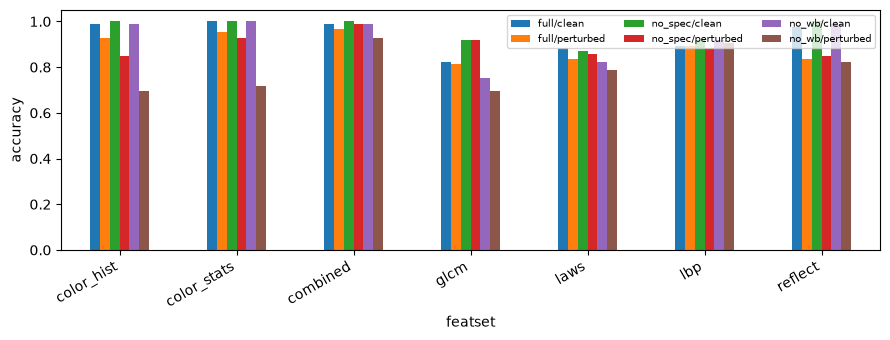

In [9]:
P_abl = pd.concat([P_main[P_main.clf == "svm"]] + [cv_eval(v, ["svm"], list(FEATSETS)) for v in ("no_wb", "no_spec")])
S_abl = score(P_abl); S_abl.to_csv(OUT / "results_ablation.csv", index=False)
display(S_abl.pivot(index="featset", columns=["variant", "cond"], values="accuracy").round(3))
fig, ax = plt.subplots(figsize=(9, 3.5)); S_abl.assign(k=S_abl.variant + "/" + S_abl.cond).pivot(index="featset", columns="k", values="accuracy").plot.bar(ax=ax)
ax.set_ylabel("accuracy"); plt.xticks(rotation=30, ha="right"); plt.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.savefig(OUT / "ablation.png", dpi=130); plt.show()

### 5.2 Best method: errors, confusion matrix, small parts, uncertain labels

best: color_stats + svm


,variant,featset,clf,cond,n,accuracy,f1_macro
10,full,color_stats,svm,clean,85,1.000,1.000
4,full,color_hist,svm,clean,85,0.988,0.991
12,full,combined,logreg,clean,85,0.988,0.991
16,full,combined,svm,clean,85,0.988,0.991
14,full,combined,rf,clean,85,0.976,0.978
2,full,color_hist,rf,clean,85,0.965,0.974


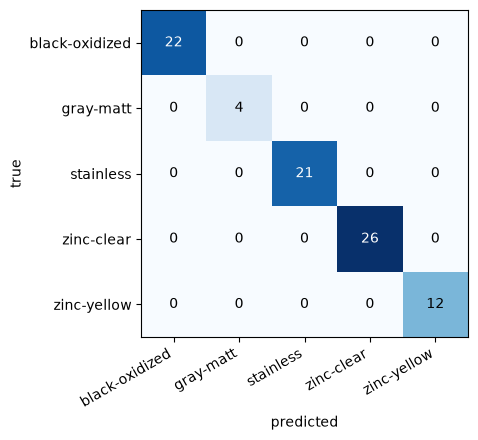

accuracy by part size (valid pixels):


,mean,count
size,,
200-1000 px,1.0,3
>1000 px,1.0,82


accuracy on parts flagged 'unsure' vs the rest:


,mean,count
unsure,,
False,1.0,85


recall per class:


,mean,count
true,,
black-oxidized,1.0,22
gray-matt,1.0,4
stainless,1.0,21
zinc-clear,1.0,26
zinc-yellow,1.0,12


,image,part_id,true,pred,n_valid,unsure


In [10]:
cand = S_main[(S_main.cond == "clean")].sort_values(["f1_macro", "accuracy"], ascending=False)
BEST_FS, BEST_CLF = cand.iloc[0].featset, cand.iloc[0].clf; print("best:", BEST_FS, "+", BEST_CLF); display(cand.head(6).round(3))
B = P_main[(P_main.featset == BEST_FS) & (P_main.clf == BEST_CLF) & (P_main.cond == "clean")]
labs = sorted(df.finish.unique()); cm = confusion_matrix(B.true, B.pred, labels=labs)
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=30, ha="right"); ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs)
for i in range(len(labs)):
    for j in range(len(labs)): ax.text(j, i, cm[i, j], ha="center", va="center", color="k" if cm[i, j] < cm.max()/2 else "w")
ax.set_xlabel("predicted"); ax.set_ylabel("true"); plt.tight_layout(); plt.savefig(OUT / "confusion_best.png", dpi=130); plt.show()
B = B.assign(size=pd.cut(B.n_valid, [0, 200, 1000, 1e9], labels=["<200 px", "200-1000 px", ">1000 px"]), ok=B.true == B.pred)
print("accuracy by part size (valid pixels):"); display(B.groupby("size").ok.agg(["mean", "count"]).round(3))
print("accuracy on parts flagged 'unsure' vs the rest:"); display(B.groupby("unsure").ok.agg(["mean", "count"]).round(3))
print("recall per class:"); display(B.groupby("true").ok.agg(["mean", "count"]).round(3))
display(B[~B.ok][["image", "part_id", "true", "pred", "n_valid", "unsure"]].sort_values(["image", "part_id"]))

## 6. Final model → every image in `inputs/`

finish,black-oxidized,gray-matt,stainless,zinc-clear,zinc-yellow
image,,,,,
screws_026.png,4,0,2,2,0
screws_027.png,4,0,2,2,0
screws_028.png,4,0,2,2,0
screws_029.png,4,0,2,2,0
screws_040.png,0,0,4,6,0
screws_041.png,0,1,2,3,3
screws_042.png,0,1,2,3,3
screws_061.png,2,1,1,4,3
screws_063.png,2,1,1,1,3


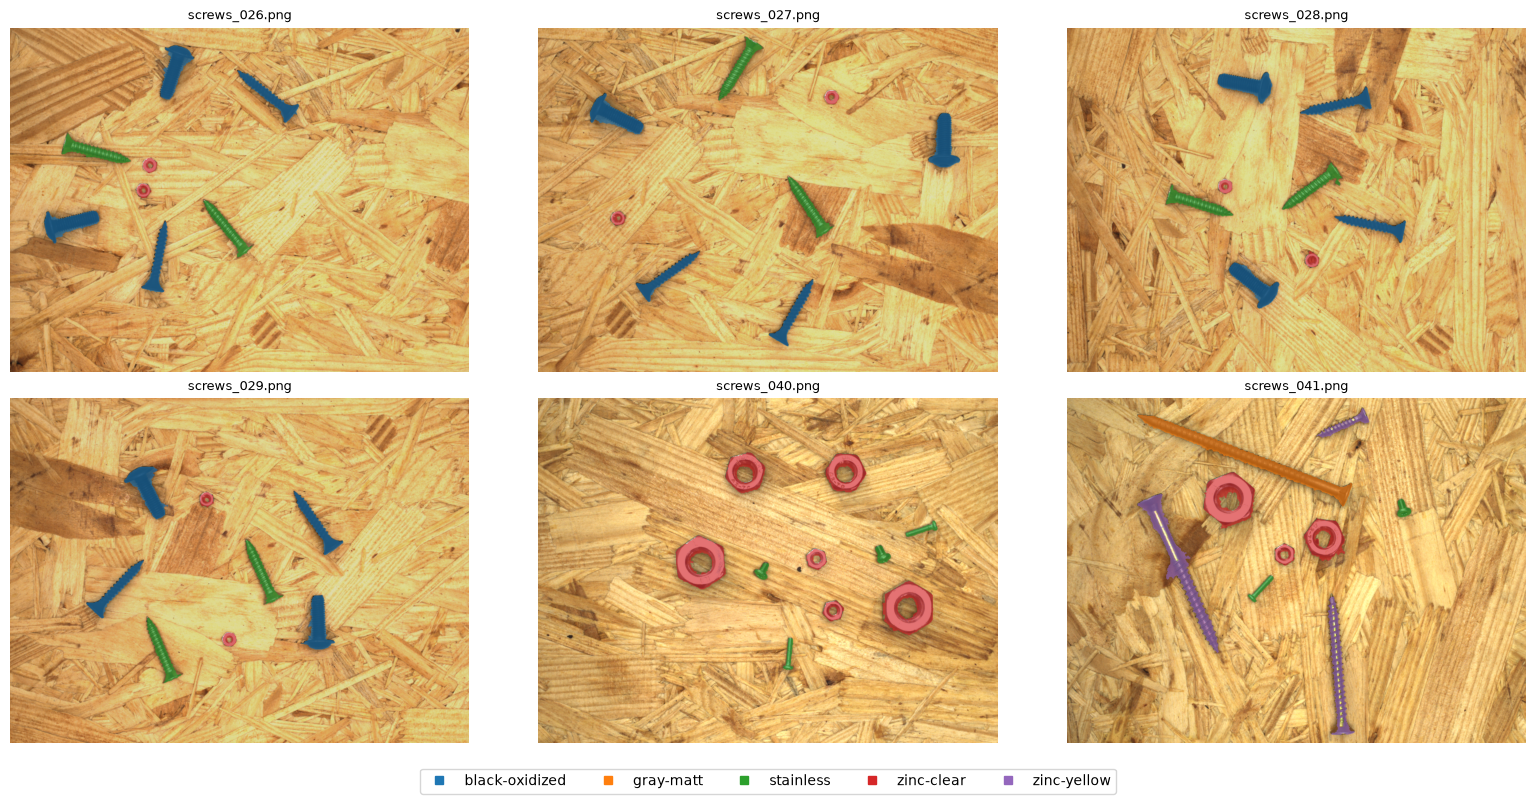

In [11]:
est, grid = CLFS[BEST_CLF]
final = GridSearchCV(est, grid, cv=GroupKFold(min(5, df.source.nunique())), scoring="f1_macro").fit(df[FEATSETS[BEST_FS]].values, df.finish.values, groups=df.source.values).best_estimator_
seg = BEST_SEG if (C1 / BEST_SEG).exists() else sorted(d.name for d in C1.iterdir() if d.is_dir())[0]
res = []; shown = []
for p in sorted(q for q in IN.iterdir() if q.suffix.lower() in EXT):
    f = C1 / seg / f"{p.stem}_labels.png"
    if not f.exists(): continue
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    lab = cv2.resize(cv2.imread(str(f), cv2.IMREAD_UNCHANGED), (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST).astype(np.int32)
    img = apply_wb(img, wood_median(img, lab)); cm_ = {}
    for i in np.unique(lab[lab > 0]):
        m = lab == i
        if m.sum() < MIN_PART_PX: continue
        ft = finish_features(img, m); cm_[int(i)] = final.predict(pd.DataFrame([ft])[FEATSETS[BEST_FS]].values)[0]
        res.append(dict(image=p.name, comp=int(i), finish=cm_[int(i)], n_valid=int(ft["n_valid"])))
    shown.append((p, img, lab, cm_))
out = pd.DataFrame(res); out.to_csv(OUT / "finish_predictions.csv", index=False)
display(out.groupby(["image", "finish"]).size().unstack(fill_value=0))
pal = dict(zip(labs, plt.cm.tab10(np.arange(len(labs)))[:, :3] * 255))
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for a, (p, img, lab, cm_) in zip(ax.ravel(), shown[:6]):
    s = 900 / max(img.shape[:2]); im2 = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA); l2 = cv2.resize(lab, (im2.shape[1], im2.shape[0]), interpolation=cv2.INTER_NEAREST)
    for i, c in cm_.items(): im2[l2 == i] = (0.35 * im2[l2 == i] + 0.65 * np.array(pal.get(c, [128, 128, 128]))).astype(np.uint8)
    a.imshow(im2); a.set_title(p.name, fontsize=9); a.axis("off")
fig.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=np.array(pal[c]) / 255, label=c) for c in labs], loc="lower center", ncol=len(labs))
plt.tight_layout(rect=(0, .05, 1, 1)); plt.savefig(OUT / "finish_overlay.png", dpi=120); plt.show()

## 7. To discuss in the report (your own words)
- Class set: how you chose / merged the finishes (evidence from images); effect of the 4 `gray-matt` parts on every metric.
- For each finish: which property is most relevant (colour: lightness, yellowness `b*`, saturation; texture: LBP uniformity, GLCM contrast, Laws' energies; reflectance: highlight fraction) – use the AUC table and heatmap.
- Method comparison with statistics (feature family × classifier; pooled out-of-fold; note the small number of parts and images).
- Illumination: ablation `no_wb` vs `full`, stress test `perturbed`; highlights: `no_spec` vs `full`.
- Thin / tiny parts: accuracy by `n_valid`; labels flagged `unsure` and how they influence the results.
- Limitations: one camera, one background, few images, possible confusion between `stainless` and `zinc-clear` on small parts.